# Modelo Oculto de Markov Para la Identificación del Regímen del activo S\&P 500  

### Estiven Hernández Alfaro - C13617


## Creación de los datos sintéticos

Estos datos se crean a partir de estados conocidos para posteriormente evaluar la validéz del método. Se parte definiendo la matriz $A$, la cual es la matriz de transición, esta almacena la probabilidad de que el estado $j$ cambie al estado $i$ o permaneza en el mismo. Una forma de entender su contenido es mediante los indices de $A$, indices repetidos (por ejemplo $A_{ii}$) es la probabilidad de que el estado en $t$ sea el mismo en el tiempo $t+1$, para el cazo de indices distintos (por ejemplo $A_{ij}$) es la probabilidad de que el estado $i$ en $t$ cambie al estado $j$ en $t+1$. Estas probabilidades son independientes del tiempo.

Matemáticamente $A$ se define como:

$$ A= [a_{ij}]  \, , \quad  
a_{ij} = P(q_t=s_j|q_{t-1}=s_i)$$

Es necesario definir $B$, esta matriz contiene la información de la Gaussiana modelo. 

$$
B= \begin{pmatrix} \mu_0 & \sigma_0 \\ \mu_1 & \sigma_1 \end{pmatrix}
$$

$\pi$ es un arreglo de probabilidad inicial:

$$\pi = [\pi_i] \, , \quad \pi_i = P(q_1=s_i)$$

Inicialmente se supone que ambos estados tienen la misma probabilidad. 

In [1]:
import numpy as np
#import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt

A = np.array(
    [
        [0.95, 0.05],
        [0.10, 0.90]
        ]
        )


B = np.array(
    [   # mu   , sigma
        [0.005,  0.01],#Estado 0 (V. Baja)
        [0.001, 0.03] #Estado 1 (V. Alta)
    ]
)

prob = np.array([0.5, 0.5]) #Es el equivalente al arreglo \pi


El siguiente paso es generar los estados ocultos $Q$ a partir de estos valores, para $T$ observaciones. Se utiliza la convención de que estados con alta volatilidad tomen el valor 1 y con baja volatilidad 0.

Posteriormente se realizan las observaciones $O$ a partir de $Q$. Las observaciones para este caso puede ser el precio del activo, el estado oculto es el régimen donde se encuentra el activo. 

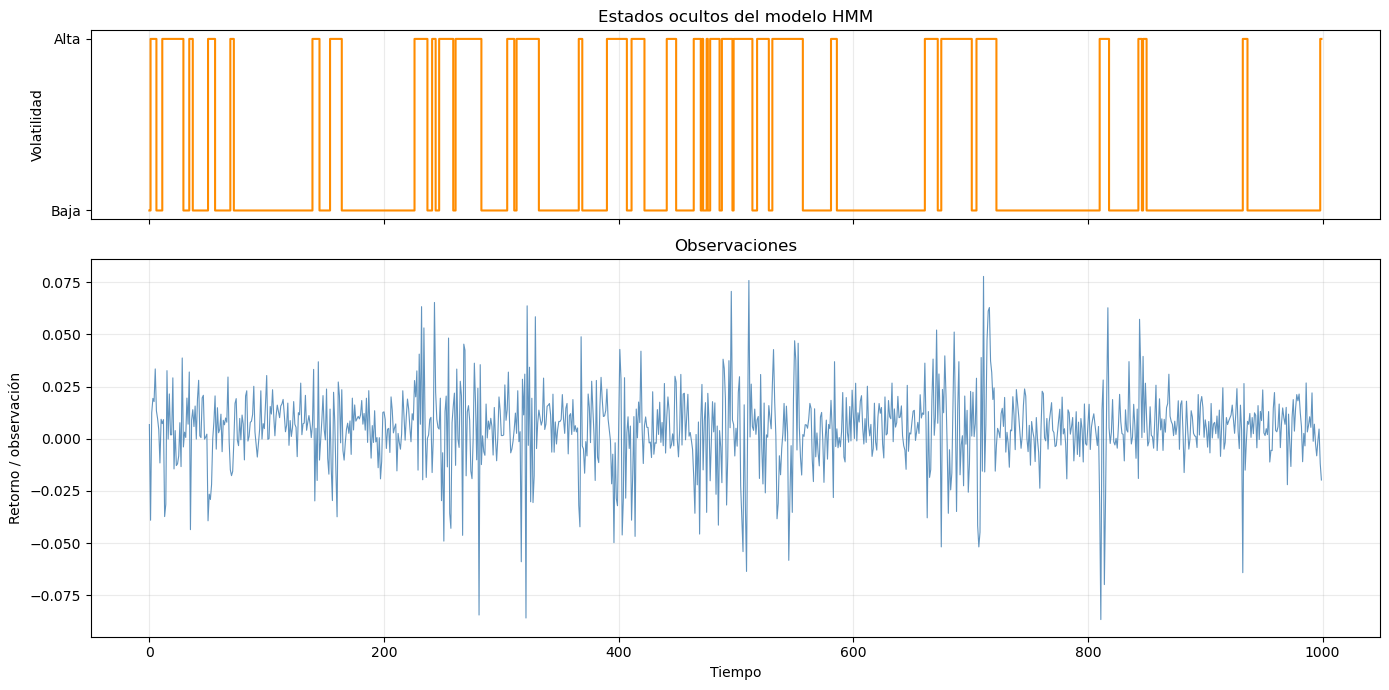

In [2]:

#Se genera Q (Estados ocultos, reprensenta si el mercado se encuentra con V.alta o V.baja)
np.random.seed(42)
T = 1000 # tiempo
Q = np.zeros(T)
Q[0] = np.random.choice([0,1],p=prob)
for i in range(T-1):
    Q[i+1] = np.random.choice([0,1], p= A[int(Q[i])])


#Genero O (observaciones)

O = np.zeros_like(Q)
for i in range(len(Q)):
    O[i] = np.random.normal(loc=B[int(Q[i])][0], scale= B[int(Q[i])][1])

t = np.arange(T)

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2]}
)

# Estados ocultos
ax1.step(t, Q, where="post", color="darkorange", linewidth=1.5)
ax1.set_yticks([0, 1], labels=["Baja", "Alta"])
ax1.set_ylabel("Volatilidad")
ax1.set_title("Estados ocultos del modelo HMM")
ax1.grid(axis="x", alpha=0.25)

# Observaciones
ax2.plot(t, O, color="steelblue", linewidth=0.8, alpha=0.85)
ax2.set_title("Observaciones")
ax2.set_xlabel("Tiempo")
ax2.set_ylabel("Retorno / observación")
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Decodificación - Algoritmo Viterbi 

El objetivo de la decodificación es descubrir la secuencia de estados ocultos que con mayor probabilidad produjo una secuencia de observaciones dada, a partir de cierto modelo $\lambda(A,B,\pi)$. Esta es la herramienta usada para recrear $Q$.
 
 El algoritmo de Viterbi se utiliza para encontrar la mejor secuencia de estados para una secuencia de observaciones.Este es un algoritmo de malla muy similar al forward (que se detalla más adelante), salvo que las probabilidades de transición se maximizan en cada paso, en lugar de sumarse.
 
Primero, se define:
$$ \delta_t(i) = \max_{q_1, q_2, \ldots, q_{t-1}} P(q_1 q_2 \ldots q_t = s_i, o_1, o_2, \ldots, o_t \mid \lambda) $$
como la probabilidad del camino de estados más probable para la secuencia parcial de observaciones.
 
El algoritmo es el siguiente:

- **Inicialización:**
$$ \delta_1(i) = \pi_i b_i(o_1), \quad 1 \leq i \leq N, \quad \psi_1(i) = 0 $$
- **Recursión:**
 $$ \delta_t(j) = \max_{1 \leq i \leq N} [\delta_{t-1}(i) a_{ij}] b_j(o_t), \quad 2 \leq t \leq T, \quad 1 \leq j \leq N $$

$$ \psi_t(j) = \arg\max_{1 \leq i \leq N} [\delta_{t-1}(i) a_{ij}], \quad 2 \leq t \leq T, \quad 1 \leq j \leq N $$
- **Terminación:**
$$ P^* = \max_{1 \leq i \leq N} [\delta_T(i)] $$
$$ q_T^* = \arg\max_{1 \leq i \leq N} [\delta_T(i)] $$
\item Reconstrucción (backtracking) de la secuencia óptima de estados:
$$ q_t^+ = \psi_{t+1}(q_{t+1}^*), \quad t = T-1, T-2, \ldots, 1 $$


### Limitaciones:

La variable de Viterbi es un producto de factores de transición y
emisión a lo largo de la secuencia:

$$\delta_t(i) = \max_{q_1,\dots,q_{t-1}} P(q_1,\dots,q_{t-1}, q_t=s_i,\; o_1,\dots,o_t \mid \lambda)$$

Con $T\sim 10^3$ pasos, ese producto decae exponencialmente y se anula al
saturar el rango de `float64` (underflow), volviendo inservible la comparación entre caminos.

La forma de solucionar esto es que, como Viterbi solo necesita identificar el camino óptimo (los `argmax`) y no el valor de su probabilidad, se trabaja en el dominio
logarítmico. El logaritmo es monótono creciente,

$$x > y \;\Longleftrightarrow\; \log x > \log y$$

por lo que preservar el orden garantiza que el `argmax` no cambia. Además
convierte los productos en sumas, que no se desbordan:

$$\delta_t(j) = \max_i \big[\, \log\delta_{t-1}(i) + \log a_{ij} \,\big] + \log b_j(o_t)$$

Así la recursión acumula sumas de log-probabilidades en lugar de productos, y el algoritmo es numéricamente estable para secuencias largas.

**Nota.** $\log 0 = -\infty$: si alguna transición tiene probabilidad exactamente cero, su log es $-\infty$ (camino imposible). Con emisiones gaussianas las densidades nunca son exactamente cero, así que no genera problemas salvo que se impongan transiciones prohibidas en $A$.






In [3]:


def Viterbi(A,B,prob):
    #Inicialización
    delta0 = np.zeros(2)
    psi = np.zeros((T,2))
    delta = np.zeros((T,2))
    for i in range(2): 
        delta0[i] = prob[i] * sp.stats.norm.pdf(O[0], loc=B[i][0], scale= B[i][1])
        
    delta[0] = np.log(delta0)
    omega = np.zeros(2)

    # Ahora, la recursión
    for t in range(1,T):
        for j in range(2):
            for i in range(2):
                omega[i] = delta[t-1,i] + np.log(A[i][j])
            delta[t,j] = np.max(omega) + np.log(sp.stats.norm.pdf(O[t], loc=B[j][0], scale= B[j][1]))
            psi[t,j] = np.argmax(omega)
    #Terminación
    P_T = np.max(delta[T-1])
    q_T = np.argmax(delta[T-1])

    # Reconstrucción (backtracking): 
    reconstruction = np.zeros(T)
    reconstruction[T-1] = q_T
    for t in range(T-2,-1,-1):
        reconstruction[t] = psi[t+1, int(reconstruction[t+1])] 

    
    return reconstruction

reconstruction = Viterbi(A,B,prob)


En los siguientes gráficos se muestra la validez en la reconstrucción de los estados ocultos mediante el algoritmo de Viterbi.

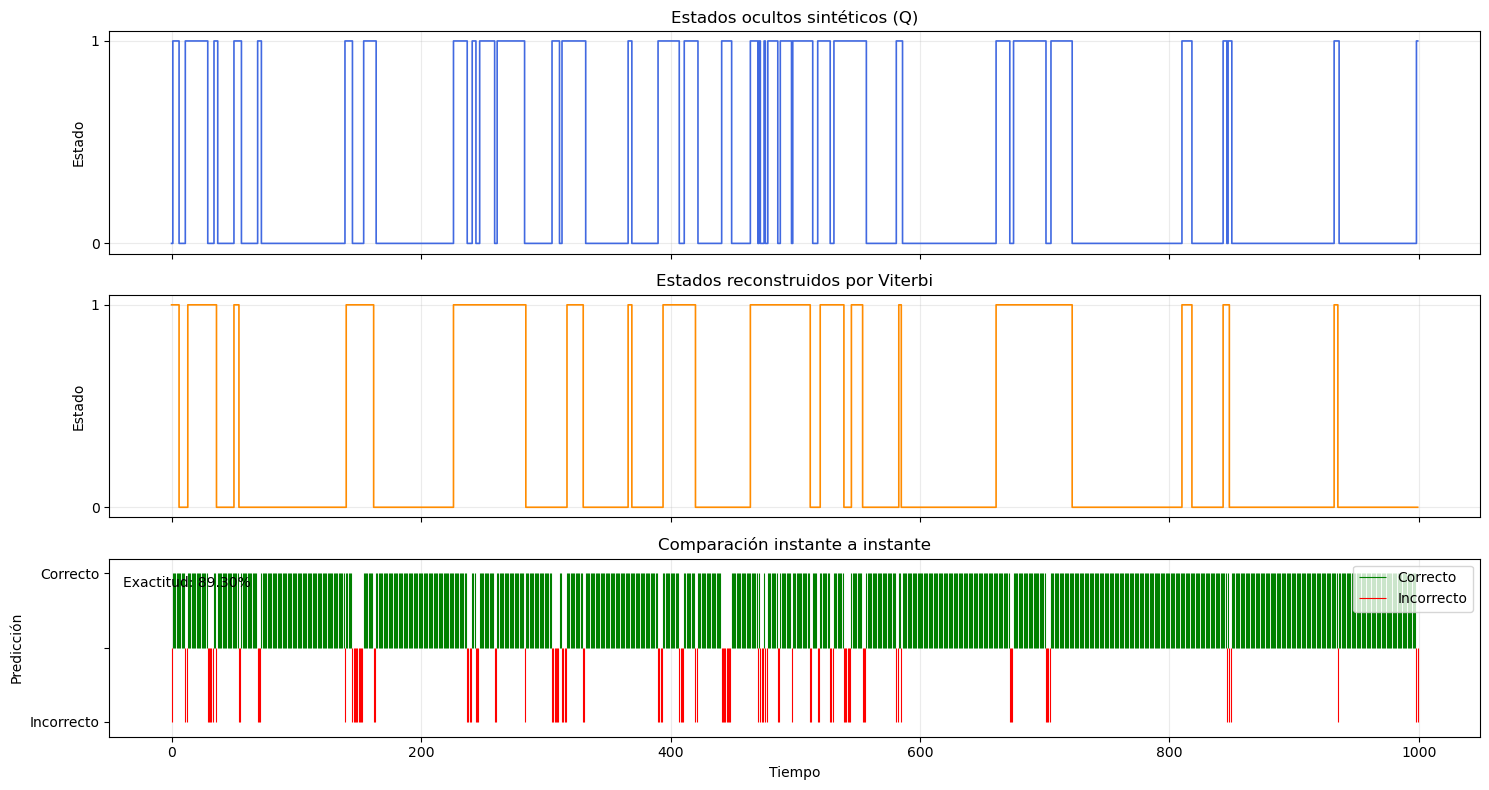

Porcentaje de acierto: 89.30%


In [4]:
t = np.arange(T)

correct = np.asarray(Q) == np.asarray(reconstruction)

fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(15, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1, 0.8]}
)

# Estados ocultos sintéticos
ax1.step(t, Q, where="post", color="royalblue", linewidth=1.2)
ax1.set_ylabel("Estado")
ax1.set_yticks([0, 1])
ax1.set_title("Estados ocultos sintéticos (Q)")
ax1.grid(alpha=0.25)

# Estados reconstruidos por Viterbi
ax2.step(t, reconstruction, where="post",
         color="darkorange", linewidth=1.2)
ax2.set_ylabel("Estado")
ax2.set_yticks([0, 1])
ax2.set_title("Estados reconstruidos por Viterbi")
ax2.grid(alpha=0.25)

# Aciertos y errores por instante
ax3.vlines(t[correct], 0, 1, color="green", linewidth=0.8,
           label="Correcto")
ax3.vlines(t[~correct], 0, -1, color="red", linewidth=0.8,
           label="Incorrecto")
ax3.set_ylim(-1.2, 1.2)
ax3.set_yticks([-1, 0, 1], labels=["Incorrecto", "", "Correcto"])
ax3.set_xlabel("Tiempo")
ax3.set_ylabel("Predicción")
ax3.set_title("Comparación instante a instante")
ax3.legend(loc="upper right")
ax3.grid(axis="x", alpha=0.25)

accuracy = np.mean(correct) * 100
ax3.text(
    0.01, 0.90, f"Exactitud: {accuracy:.2f}%",
    transform=ax3.transAxes, va="top"
)

plt.tight_layout()
plt.show()

accuracy = np.mean(np.asarray(Q) == np.asarray(reconstruction)) * 100

print(f"Porcentaje de acierto: {accuracy:.2f}%")

## Algoritmos Forward y Backward

En esta sección se exponen los algoritmos Forward y Backward, los cuales son empleados en el método de Waum-Welch.

Estos algoritmos utilizan la **densidad de observación continúa** $b_j(o_t)$

Se asume observaciones discretas tomadas de un alfabeto finito, sin embargo, los retornos logarítmicos diarios son continuos, por lo que la emisión debe modelarse mediante una densidad de probabilidad. La forma general que admite reestimación es una mezcla finita de densidades gaussianas:
 
$$ b_j(o) = \sum_{m=1}^{M} c_{jm}\, \mathcal{N}\big(o,\, \mu_{jm},\, U_{jm}\big), \quad 1 \leq j \leq N $$
 
donde $c_{jm}$ es el peso de la $m$-ésima componente de la mezcla en el estado $j$, con $\sum_{m=1}^{M} c_{jm} = 1$ y $c_{jm} \geq 0$, y $\mu_{jm}$, $U_{jm}$ son la media y la covarianza de dicha componente. 
 
En este proyecto se emplea el caso más simple $M = 1$, es decir, una única gaussiana por estado ($c_{j1} = 1$), de modo que cada régimen queda caracterizado por una media $\mu_j$ y una varianza $\sigma_j^2$:
 
$$ b_j(o) = \mathcal{N}\big(o,\, \mu_j,\, \sigma_j^2\big) = \frac{1}{\sqrt{2\pi\sigma_j^2}} \exp\!\left(-\frac{(o-\mu_j)^2}{2\sigma_j^2}\right) $$
 


### Forward
Dado un HMM y una secuencia de observaciones, se quiere poder calcular $P(O \mid \lambda)$, la probabilidad de la secuencia de observaciones. La probabilidad de las observaciones $O$ para una secuencia de estados específica $Q$ es:
$$ P(O \mid Q, \lambda) = \prod_{t=1}^{T} P(o_t \mid q_t, \lambda) = b_{q_1}(o_1) \times b_{q_2}(o_2) \cdots b_{q_T}(o_T) $$
y la probabilidad de la secuencia de estados es:
$$ P(Q \mid \lambda) = \pi_{q_1} a_{q_1 q_2} a_{q_2 q_3} \cdots a_{q_{T-1} q_T} $$
de modo que se puede calcular la probabilidad de las observaciones dado el modelo como:
$$
 \begin{align*}
     P(O \mid \lambda) = \sum_Q P(O, Q, \lambda) P(Q, \lambda) =  \\\sum_{q_1 \ldots q_T} \pi_{q_1} b_{q_1}(o_1) a_{q_1 q_2} b_{q_2}(o_2) \cdots a_{q_{T-1} q_T} b_{q_T}(o_T) 
 \end{align*}
$$
Este resultado permite evaluar la probabilidad de $O$, pero evaluarlo directamente sería exponencial en $T$.
 
Un mejor enfoque consiste en reconocer que la evaluación directa del último resultado implicaría muchos cálculos redundantes, y por lo tanto almacenar en caché los cálculos puede reducir la complejidad. 

 El caché se implementa como una malla (trellis) de estados en cada instante de tiempo, calculando el valor almacenado (llamado $\alpha$) para cada estado como una suma sobre todos los estados del instante de tiempo anterior. Entonces, $\alpha$ (también conocida como variable forward) es la probabilidad de la secuencia parcial de observaciones $o_1, o_2, \ldots, o_t$ y del estado $s_i$ en el instante $t$. 
 

$$ \alpha_t(i) = P(o_1 o_2, \ldots, o_t, q_t = s_i \mid \lambda) $$
Si se recorre la malla rellenando los valores de $\alpha$, la suma de la última columna de la malla será igual a la probabilidad de la secuencia de observaciones.
 
El algoritmo para este proceso se denomina algoritmo hacia adelante (forward) y se consisten en:

- **Inicialización:**
$$ \alpha_1(i) = \pi_i b_i(o_1), \quad 1 \leq i \leq N $$

- **Inducción:**
 $$ \alpha_{t+1}(j) = \left[ \sum_{i=1}^N \alpha_t(i) a_{ij} \right] b_j(o_{t+1}), \quad 1 \leq t \leq T-1, \quad 1 \leq j \leq N $$
 - **Finalización:**
  $$ P(O \mid \lambda) = \sum_{i=1}^N \alpha_T(i) $$




### Backward


De forma simétrica a la variable forward, se define la variable hacia atrás (backward) como la probabilidad de la secuencia parcial de observaciones desde el instante $t+1$ hasta el final, condicionada a estar en el estado $s_i$ en el instante $t$:
 
$$ \beta_t(i) = P(o_{t+1} o_{t+2} \cdots o_T \mid q_t = s_i, \lambda) $$
 
Se calcula inductivamente hacia atrás mediante los siguientes pasos:
 
- **Inicialización:**
$$ \beta_T(i) = 1, \quad 1 \leq i \leq N $$
- **Inducción:**
   $$
   \beta_t(i) = \sum_{j=1}^{N} a_{ij}\, b_j(o_{t+1})\, \beta_{t+1}(j), \qquad t = T-1, T-2, \ldots, 1, \quad 1 \leq i \leq N 
   $$



 
La inicialización $\beta_T(i) = 1$ es una convención arbitraria que hace consistentes las fórmulas posteriores; no se deduce de una interpretación probabilística directa.


### Limitaciones Forward-Backward

Las variables forward y backward son probabilidades conjuntas
sobre toda la secuencia parcial de observaciones:

$$\alpha_t(i) = P(o_1,\dots,o_t, Z_t=i \mid \lambda)$$

A cada paso se acumulan productos de factores de transición y emisión. Con
$T\sim 10^3$ pasos, ese producto crece o decae exponencialmente y satura el rango de `float64` (se vuelve `0` o `inf`) alrededor de $t\sim 50$–$100$. Sin corregirlo, el algoritmo entrega resifuos numéricos.

En el forward, la forma de solucionar este problema es que en cada instante $t$ se normaliza $\alpha_t$ para que sume 1, guardando la constante de normalización $c_t$:

$$c_t = \sum_i \bar\alpha_t(i), \qquad \hat\alpha_t(i) = \frac{\bar\alpha_t(i)}{c_t}$$

El paso siguiente de la recursión usa el $\hat\alpha_{t-1}$ ya escalado, de modo que los valores se mantienen en $[0,1]$ en todo momento.

Las constantes no se descartan: su producto reconstruye la
verosimilitud total. Para evitar que ese producto vuelva a desbordar, se trabaja
en logaritmo:

$$P(O\mid\lambda) = \prod_{t=1}^{T} c_t \quad\Longrightarrow\quad
\log P(O\mid\lambda) = \sum_{t=1}^{T} \log c_t$$

En el backward se reescala $\beta_t$ por el mismo motivo numérico, pero sus
constantes no entran en $\log P$ (la verosimilitud queda fijada por los
$c_t$ del forward).

 




In [5]:
def Forward(pi,mu,sigma,A):
    alpha0 = np.zeros(2)
    c_t = np.zeros(T)
    for i in range(2):
        alpha0[i] = pi[i] * sp.stats.norm.pdf(O[0], loc=mu[i], scale= sigma[i])
    alpha = np.zeros((T,2))

    c_t[0] = alpha0.sum()
    alpha[0] = alpha0 / c_t[0] 

    for t in range(1,T):
        for j in range(2):
            for i in range(2):
                alpha[t, j] += alpha[t-1,i] * A[i,j] *  sp.stats.norm.pdf(O[t], loc=mu[j], scale= sigma[j])
        c_t[t] = alpha[t].sum()
        alpha[t] = alpha[t] / c_t[t]

    P = np.sum(np.log(c_t))
    return alpha, P # Devuelve los alphas y la probabilidad P(O|lambda)



def Backward(A, mu, sigma):
    c_t = np.zeros(T)
    beta = np.zeros((T,2))
    beta[T-1] = np.ones((1,2))/2.0 #se normaliza nuevamente

    for t in range(T-2,-1,-1):
        for i in range(2):
            for j in range(2):
                beta[t,i] += A[i][j] * sp.stats.norm.pdf(O[t+1], loc=mu[j], scale= sigma[j]) * beta[t+1,j]
        c_t[t] = beta[t].sum()
        beta[t] = beta[t]/c_t[t]

    return beta

## Aprendizaje no supervisado: Algoritmo Baum-Welch

Baum-Welch es la herramienta principal utilizada para optimizar el modelo $\lambda(A,B,\pi)$ que mejor encaja con las observaciones, maximizando $P(O|\lambda)$, a partir únicamente de la secuencia de observaciones, sin conocer la secuencia de estados. Este es el caso relevante para la detección de regímenes, pues los regímenes de mercado no se observan directamente. No existe una forma analítica cerrada de resolver este problema; lo que sí puede hacerse es elegir $\lambda$ tal que $P(O \mid \lambda)$ sea un máximo local, mediante el procedimiento iterativo de Baum-Welch, que es un caso particular del algoritmo de esperanza-maximización (EM).

 
Se define la probabilidad de estar en el estado $s_i$ en el instante $t$ y en el estado $s_j$ en $t+1$, dada la observación y el modelo:
 
$$ \begin{align*}
    \xi_t(i,j) = P(q_t = s_i, q_{t+1} = s_j \mid O, \lambda)\\ = \frac{\alpha_t(i)\, a_{ij}\, b_j(o_{t+1})\, \beta_{t+1}(j)}{\sum_{i=1}^{N} \sum_{j=1}^{N} \alpha_t(i)\, a_{ij}\, b_j(o_{t+1})\, \beta_{t+1}(j)} 
\end{align*}$$
 
y la probabilidad de estar en el estado $s_i$ en el instante $t$:
 
$$ \gamma_t(i) = P(q_t = s_i \mid O, \lambda) = \sum_{j=1}^{N} \xi_t(i,j) $$
 
La suma de estas cantidades sobre el tiempo tiene una interpretación de conteos esperados, que es la clave conceptual del algoritmo:
 
$$ \sum_{t=1}^{T-1} \gamma_t(i) = \text{número esperado de transiciones desde } s_i $$
$$ \sum_{t=1}^{T-1} \xi_t(i,j) = \text{número esperado de transiciones de } s_i \text{ a } s_j $$
 
Con ello, las fórmulas de reestimación son:
 
$$ \bar\pi_i = \gamma_1(i) $$
$$ \bar a_{ij} = \frac{\sum_{t=1}^{T-1} \xi_t(i,j)}{\sum_{t=1}^{T-1} \gamma_t(i)} $$
 
Para el caso de emisión gaussiana ($M = 1$), la media y la varianza de cada estado se reestiman como promedios ponderados por $\gamma_t(j)$:
 
$$ \bar\mu_j = \frac{\sum_{t=1}^{T} \gamma_t(j)\, o_t}{\sum_{t=1}^{T} \gamma_t(j)} $$
$$ \bar\sigma_j^2 = \frac{\sum_{t=1}^{T} \gamma_t(j)\, (o_t - \mu_j)^2}{\sum_{t=1}^{T} \gamma_t(j)} $$
 
La intuición es directa: si se observaran los estados, $a_{ij}$ se estimaría contando transiciones; como no se observan, se cuentan transiciones esperadas bajo la distribución posterior actual y se itera.
 
La garantía teórica del método es que, maximizando la función auxiliar
 
$$ Q(\lambda, \bar\lambda) = \sum_Q P(Q \mid O, \lambda) \log\big[P(O, Q \mid \bar\lambda)\big] $$
 
se cumple
 
$$ \max_{\bar\lambda}\big[Q(\lambda, \bar\lambda)\big] \;\Rightarrow\; P(O \mid \bar\lambda) \geq P(O \mid \lambda) $$
 
es decir, cada iteración no disminuye la verosimilitud, y el procedimiento converge a un punto crítico. 
 
 
En la práctica esto se refiere a que por cada iteración se cálcula una nueva probabilidad $ P(O|\tilde \lambda)$ con el nuevo estado $\tilde \lambda$ y se compara con la probabilidad inicial $P(O|\lambda)$ del estado $\lambda$ definiendo un  $\epsilon$ tal que 

$$
P(O|\tilde \lambda) - P(O| \lambda) \leq \epsilon
$$

En caso de que esta condición se cumpla, entonces el estado $\tilde \lambda$ será el usado por Viterbi para recrear el estado oculto $Q$. En caso contrario,  el nuevo estado pasa a ser el antiguo $\tilde \lambda \rightarrow \lambda$ y se recalcula un nuevo $\tilde \lambda$ que maximice $ P(O|\tilde \lambda)$. El búcle se repite hasta que se cumpla la condición. Como $\tilde \lambda$ es la entrada que recibe Viterbi y el algoritmo de Baum-Welch optimiza $\tilde \lambda$, este se considera un aprendizaje no supervizado.

In [6]:
def compute_xi(A,mu,sigma, alpha, beta):
    xi = np.zeros((T-1,2,2)) #Es un tensor de tamaño Nx2x2
    for t in range(T-1):
        for i in range(2):
            for j in range(2):
                xi[t,i,j] = alpha[t,i] * A[i,j] * sp.stats.norm.pdf(O[t+1], loc=mu[j], scale= sigma[j]) * beta[t+1,j]
        xi[t] = xi[t]/ xi[t].sum()
    return xi

def gamma_t(xi): 
    #Calculo de la probabilidad de estar en el estado s_i 
    #en el instante t (gamma_t(i))
    return xi.sum(axis=2)

def sort_states_by_sigma(pi, A, mu, sigma): 
    #El algoritmo puede tener un problema de label
     #esta función es para corregirlo
    perm = np.argsort(sigma)          # índices que ordenan sigma de menor a mayor
    pi_s    = pi[perm]
    mu_s    = mu[perm]
    sigma_s = sigma[perm]
    A_s     = A[perm][:, perm]        # permuta filas y columnas a la vez
    B_s     = np.column_stack([mu_s, sigma_s])   # B[i] = [mu_i, sigma_i]
    return pi_s, A_s, mu_s, sigma_s, B_s



def Restimation_Fuction( A, mu, sigma, pi):

    beta = Backward(A, mu, sigma)
    alpha , _ = Forward(pi,mu,sigma,A)

    xi = compute_xi(A,mu,sigma, alpha, beta)

    gamma_prob = gamma_t(xi)

    # Ahora se calcula la reestimación de pi, A, mu, simga²

    pi_re = gamma_prob[0]

    A_re = xi.sum(axis=0) / gamma_prob.sum(axis=0).reshape(2,1)

    mu_re = (gamma_prob * O[:T-1].reshape(T-1,1)).sum(axis=0) / gamma_prob.sum(axis=0)

    sigma_re = np.sqrt((gamma_prob *(O[:T-1].reshape(T-1,1)-mu_re)**2).sum(axis=0) / gamma_prob.sum(axis=0))

    return pi_re, A_re, mu_re, sigma_re



def Baum_Welch(pi,mu,sigma,A): #Al usarlo utiliza los datos estimados iniciales 
    ME_CONDITION = False 
    epsilon = 1e-6

    _, P_0 = Forward(pi,mu,sigma,A)

    while ME_CONDITION == False:
        pi_re, A_re, mu_re, sigma_re = Restimation_Fuction( A, mu, sigma, pi)
        _, P_i = Forward(pi_re,mu_re,sigma_re,A_re)
        if P_i - P_0 <= epsilon:
            ME_CONDITION = True
        else:
            P_0 = P_i
            A = A_re
            mu = mu_re
            sigma = sigma_re
            pi = pi_re

    return P_i, *sort_states_by_sigma(pi_re, A_re, mu_re, sigma_re) # pi_s, A_s, mu_s, sigma_s, B_s




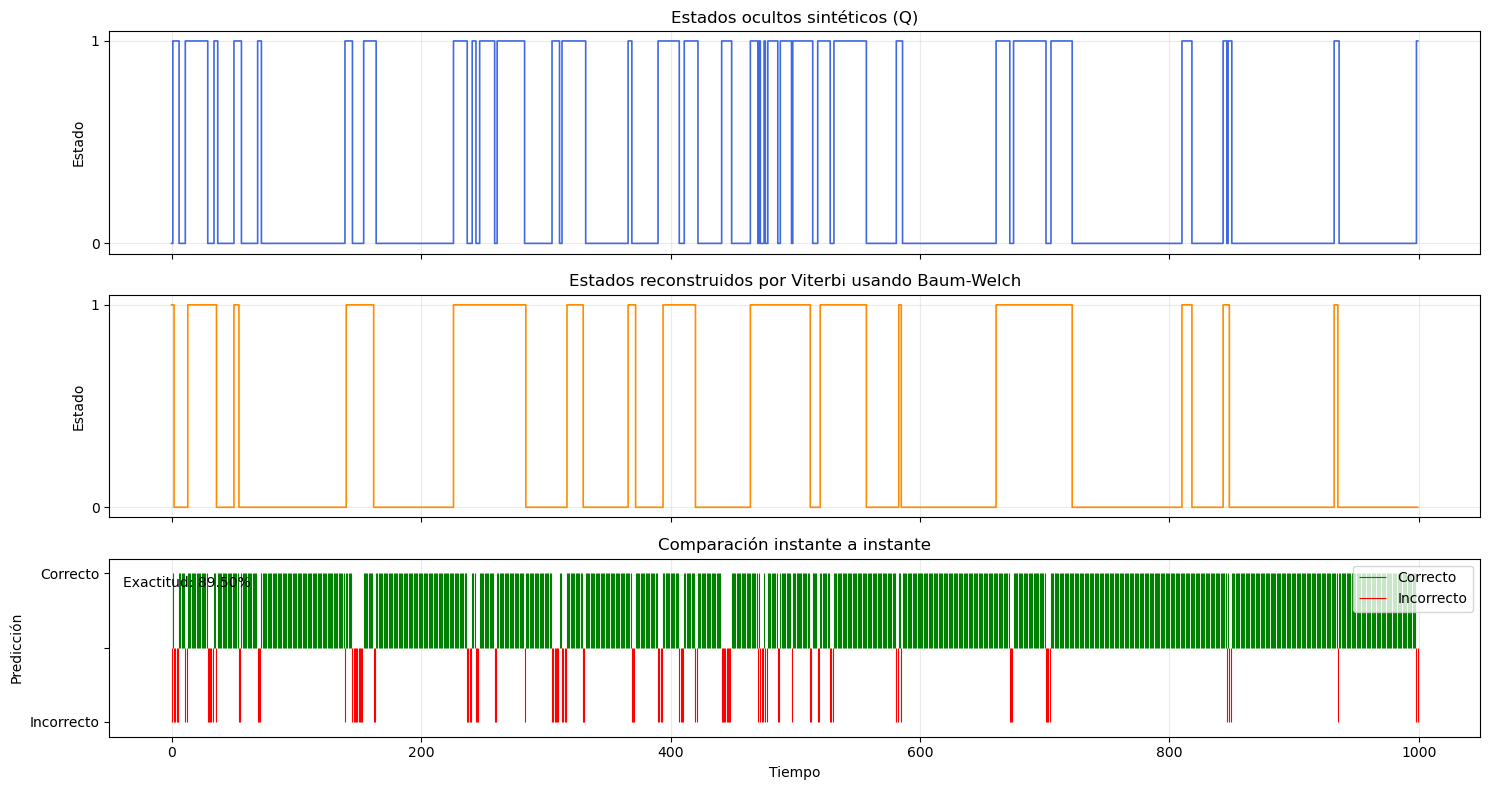

Porcentaje de acierto: 89.50%
Means:
2741.906054644073

Covariances:
[[0.96241392 0.03758608]
 [0.07877757 0.92122243]]

Standar deviation:
[0.0100621  0.02877709]

Transition matrix:
[1.92532511e-27 1.00000000e+00]

Start probabilities:
2741.906054644073

Emission parameters (mu, sigma):
[[0.00643596 0.0100621 ]
 [0.00179387 0.02877709]]



In [11]:


# Al hacer una prueba


mu0 = np.array([0.003, -0.003])
sigma0 = np.array([0.01, 0.04])

P_i, pi_re, A_re, mu_re, sigma_re, B_re = Baum_Welch(prob,mu0,sigma0,A) #


WB_reconstruction = Viterbi(A_re,B_re,pi_re)


t = np.arange(T)

correct = np.asarray(Q) == np.asarray(WB_reconstruction)

fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(15, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1, 0.8]}
)

# Estados ocultos sintéticos
ax1.step(t, Q, where="post", color="royalblue", linewidth=1.2)
ax1.set_ylabel("Estado")
ax1.set_yticks([0, 1])
ax1.set_title("Estados ocultos sintéticos (Q)")
ax1.grid(alpha=0.25)

# Estados reconstruidos por Viterbi
ax2.step(t, WB_reconstruction, where="post",
         color="darkorange", linewidth=1.2)
ax2.set_ylabel("Estado")
ax2.set_yticks([0, 1])
ax2.set_title("Estados reconstruidos por Viterbi usando Baum-Welch")
ax2.grid(alpha=0.25)

# Aciertos y errores por instante
ax3.vlines(t[correct], 0, 1, color="green", linewidth=0.8,
           label="Correcto")
ax3.vlines(t[~correct], 0, -1, color="red", linewidth=0.8,
           label="Incorrecto")
ax3.set_ylim(-1.2, 1.2)
ax3.set_yticks([-1, 0, 1], labels=["Incorrecto", "", "Correcto"])
ax3.set_xlabel("Tiempo")
ax3.set_ylabel("Predicción")
ax3.set_title("Comparación instante a instante")
ax3.legend(loc="upper right")
ax3.grid(axis="x", alpha=0.25)

accuracy = np.mean(correct) * 100
ax3.text(
    0.01, 0.90, f"Exactitud: {accuracy:.2f}%",
    transform=ax3.transAxes, va="top"
)

plt.tight_layout()
plt.show()

accuracy = np.mean(np.asarray(Q) == np.asarray(WB_reconstruction)) * 100

print(f"Porcentaje de acierto: {accuracy:.2f}%")

print(f"Means:\n{P_i}\n")
print(f"Covariances:\n{A_re}\n")
print(f"Standar deviation:\n{sigma_re}\n")
print(f"Transition matrix:\n{pi_re}\n")
print(f"Start probabilities:\n{P_i}\n")
print(f"Emission parameters (mu, sigma):\n{B_re}\n")




## Implementación de HMMlearn

La librería de python `hmmlearn` resuelve los problemas de los métodos de Markov ocultos de forma sencilla. Esta permite realizar el algoritmo de Baum-Welch para encontrar el estado $\lambda(A,B,\pi)$ optimo y además, permite de forma sencilla obtener la secuencia de estados ocultos mediante Viterbi o mediante las probabilidades suavizadas $\gamma_t(i)$ (la cual no se discute en este trabajo). Esta librería utiliza las mismas técnicas planteadas anteriormente y de una manera más rápida. 


In [8]:
from hmmlearn import hmm


"""
-Se empieza creando un modelo vacío. 
-la cantidad de componentes está determinada por la cantidad 
de estados con los que se trabaja, en nuestro caso son 2. 
-El uso de covariance_type="spherical" se debe a que cada estado tiene una única varianza escalar (sigma^2).
La observación es 1-dimensional (retorno log diario), así que la "matriz" de
covarianza se reduce a un solo número por estado. "spherical" es la
representación más directa de eso: una varianza por régimen.
- n_iter especifica el número máximo de iteraciones permitido (cuantas veces se recalcula la probabilidad maxima local)
- tol es el equivalente en mi código a epsilon, este indica la diferencia máxima que tiene que haber entre la probabilidad 
actual y la pasada
"""
model = hmm.GaussianHMM(n_components=2, covariance_type="spherical",
                        n_iter=1000, tol=1e-6)

"""
Incialmente las observaciones O es un arreglo de T entradas
hmmlearn trabaja con un arreglo de [T,1]
por esta razón es necesario utilizar .reshape()
"""
model.fit( O.reshape(T,1)) # Realiza Baum-Welch en una sola línea

#sort_states_by_sigma(pi, A, mu, sigma) ->  pi_s, A_s, mu_s, sigma_s, B_s

pi_learn, A_learn, mu_learn, sigma_learn, B_learn = sort_states_by_sigma(
    pi=model.startprob_,
    A = model.transmat_,
    mu= model.means_.ravel(),
    sigma= np.sqrt(model.covars_).ravel()
    )



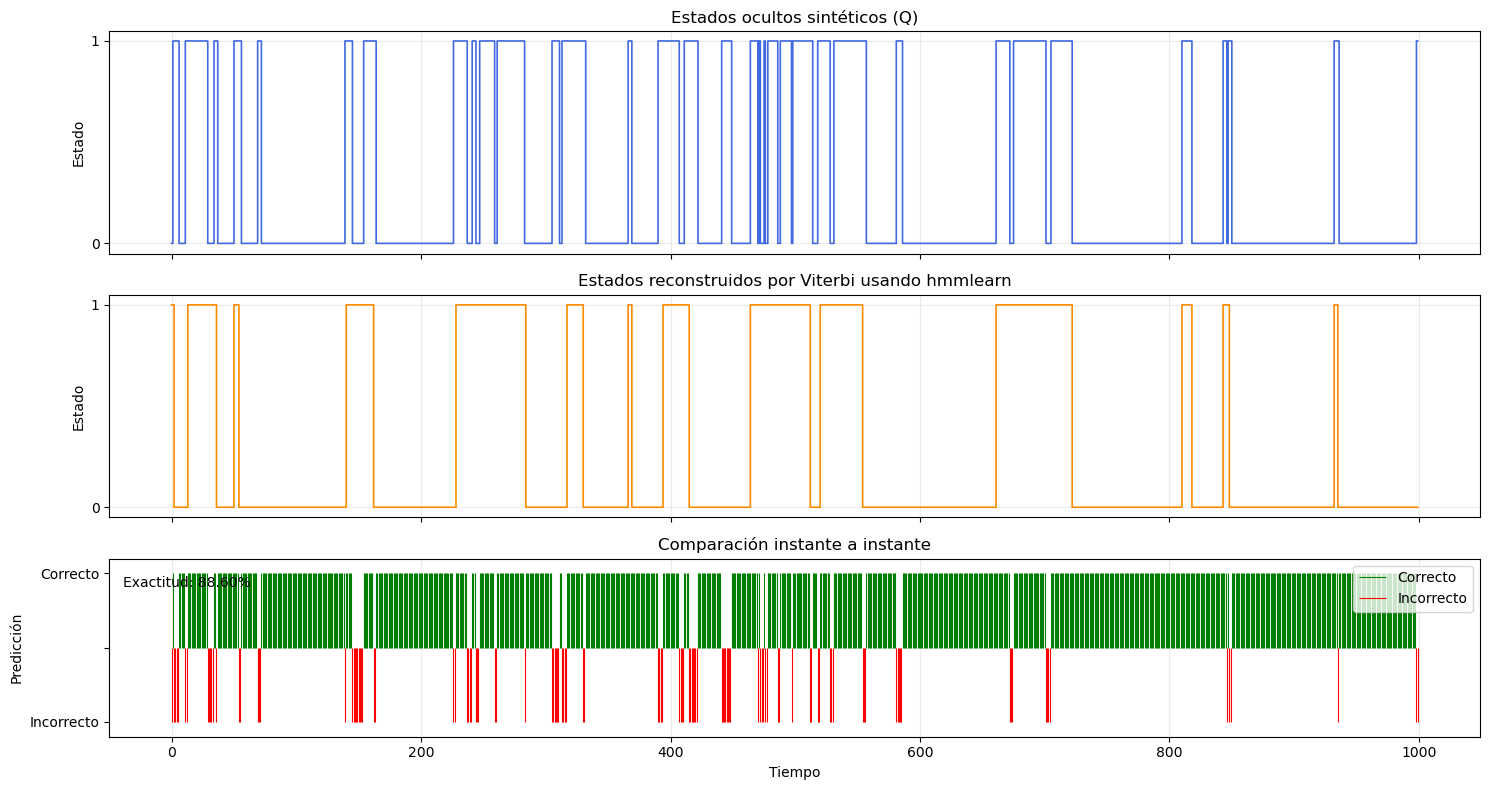

Porcentaje de acierto: 88.60%
Means:
[0.00630596 0.00147311]

Covariances:
[0.00012491 0.00092612]

Standard deviation:
[0.01117643 0.03043217]

Transition matrix:
[[0.96492822 0.03507178]
 [0.08722327 0.91277673]]

Start probabilities:
[2.7495169e-31 1.0000000e+00]

Emission parameters (mu, sigma):
[[0.00630596 0.01117643]
 [0.00147311 0.03043217]]

True
ConvergenceMonitor(
    history=[2153.0614800332824, 2568.0685945915993, 2570.657300534616, 2575.1448295097816, 2581.7605299245192, 2588.1714749101884, 2592.858195346933, 2596.0974359480683, 2598.4419946775697, 2600.247560646629, 2601.705058796136, 2602.9184590530044, 2603.949175197446, 2604.8371443930437, 2605.6107004384226, 2606.2913877285155, 2606.896451569114, 2607.4402167661096, 2607.9349100264817, 2608.3911916289367, 2608.818528119618, 2609.225473697909, 2609.6198962875933, 2610.009168281456, 2610.400333729515, 2610.8002594769946, 2611.215775554308, 2611.653809017494, 2612.121514963564, 2612.6264083606916, 2613.1765005315106, 26

In [9]:
hmmlearn_reconstruction = Viterbi(A=A_learn, B=B_learn, prob=pi_learn)

correct = np.asarray(Q) == np.asarray(hmmlearn_reconstruction)

fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1,
    figsize=(15, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1, 0.8]}
)

# Estados ocultos sintéticos
ax1.step(t, Q, where="post", color="royalblue", linewidth=1.2)
ax1.set_ylabel("Estado")
ax1.set_yticks([0, 1])
ax1.set_title("Estados ocultos sintéticos (Q)")
ax1.grid(alpha=0.25)

# Estados reconstruidos por Viterbi
ax2.step(t, hmmlearn_reconstruction, where="post",
         color="darkorange", linewidth=1.2)
ax2.set_ylabel("Estado")
ax2.set_yticks([0, 1])
ax2.set_title("Estados reconstruidos por Viterbi usando hmmlearn")
ax2.grid(alpha=0.25)

# Aciertos y errores por instante
ax3.vlines(t[correct], 0, 1, color="green", linewidth=0.8,
           label="Correcto")
ax3.vlines(t[~correct], 0, -1, color="red", linewidth=0.8,
           label="Incorrecto")
ax3.set_ylim(-1.2, 1.2)
ax3.set_yticks([-1, 0, 1], labels=["Incorrecto", "", "Correcto"])
ax3.set_xlabel("Tiempo")
ax3.set_ylabel("Predicción")
ax3.set_title("Comparación instante a instante")
ax3.legend(loc="upper right")
ax3.grid(axis="x", alpha=0.25)

accuracy = np.mean(correct) * 100
ax3.text(
    0.01, 0.90, f"Exactitud: {accuracy:.2f}%",
    transform=ax3.transAxes, va="top"
)

plt.tight_layout()
plt.show()

accuracy = np.mean(np.asarray(Q) == np.asarray(hmmlearn_reconstruction)) * 100

print(f"Porcentaje de acierto: {accuracy:.2f}%")

print(f"Means:\n{mu_learn}\n")
print(f"Covariances:\n{sigma_learn**2}\n")
print(f"Standard deviation:\n{sigma_learn}\n")
print(f"Transition matrix:\n{A_learn}\n")
print(f"Start probabilities:\n{pi_learn}\n")
print(f"Emission parameters (mu, sigma):\n{B_learn}\n")

print(model.monitor_.converged)
print(model.monitor_)




## Baum-Welch manual vs. hmmlearn

Ambas implementaciones se ajustaron sobre la **misma** secuencia sintética $O$
(`np.random.seed(42)`, T = 1 000), partiendo de inicializaciones independientes.
Los estados se ordenaron por $\sigma$ creciente para neutralizar el *label switching*
antes de comparar.

| Parámetro | Verdadero | Baum-Welch (manual) | hmmlearn |
|---|---|---|---|
| μ (estado 0, baja vol) | 0.005 | 0.00644 | 0.00631 |
| μ (estado 1, alta vol) | −0.001 | 0.00179 | 0.00147 |
| σ (estado 0, baja vol) | 0.010 | 0.01006 | 0.01118 |
| σ (estado 1, alta vol) | 0.030 | 0.02878 | 0.03043 |
| A | [[0.95, 0.05], [0.10, 0.90]] | [[0.962, 0.038], [0.079, 0.921]] | [[0.965, 0.035], [0.087, 0.913]] |
| π | [0.5, 0.5] | [≈0, 1] | [≈0, 1] |
| log P(O\|λ) | — | 2741.91 | 2737.49 |
| Exactitud Viterbi vs. estados reales | — | 89.5 % | 88.6 % |

**Interpretación.** Los dos métodos llegan básicamente al mismo modelo. La
matriz de transición sale casi igual, las desviaciones estándar coinciden
salvo por ruido, y en ambos casos Viterbi acierta el régimen real en ~89 % de
los días. El log P difiere por poco (≈4), y eso es esperable: EM converge a
óptimos locales que dependen de dónde arranca cada uno. Mi Baum-Welch parte de
parámetros que fijé a mano y hmmlearn parte de su propia inicialización, así
que es normal que terminen en puntos apenas distintos; los dos son válidos. El
~11 % de error de Viterbi no se puede evitar: las dos gaussianas se solapan, y
cuando un retorno cae en esa zona, no hay forma de saber con certeza de qué
régimen vino.

**Conclusión.** La implementación a mano de forward–backward, Viterbi y
Baum-Welch da lo mismo que una librería estándar sobre los mismos datos. 

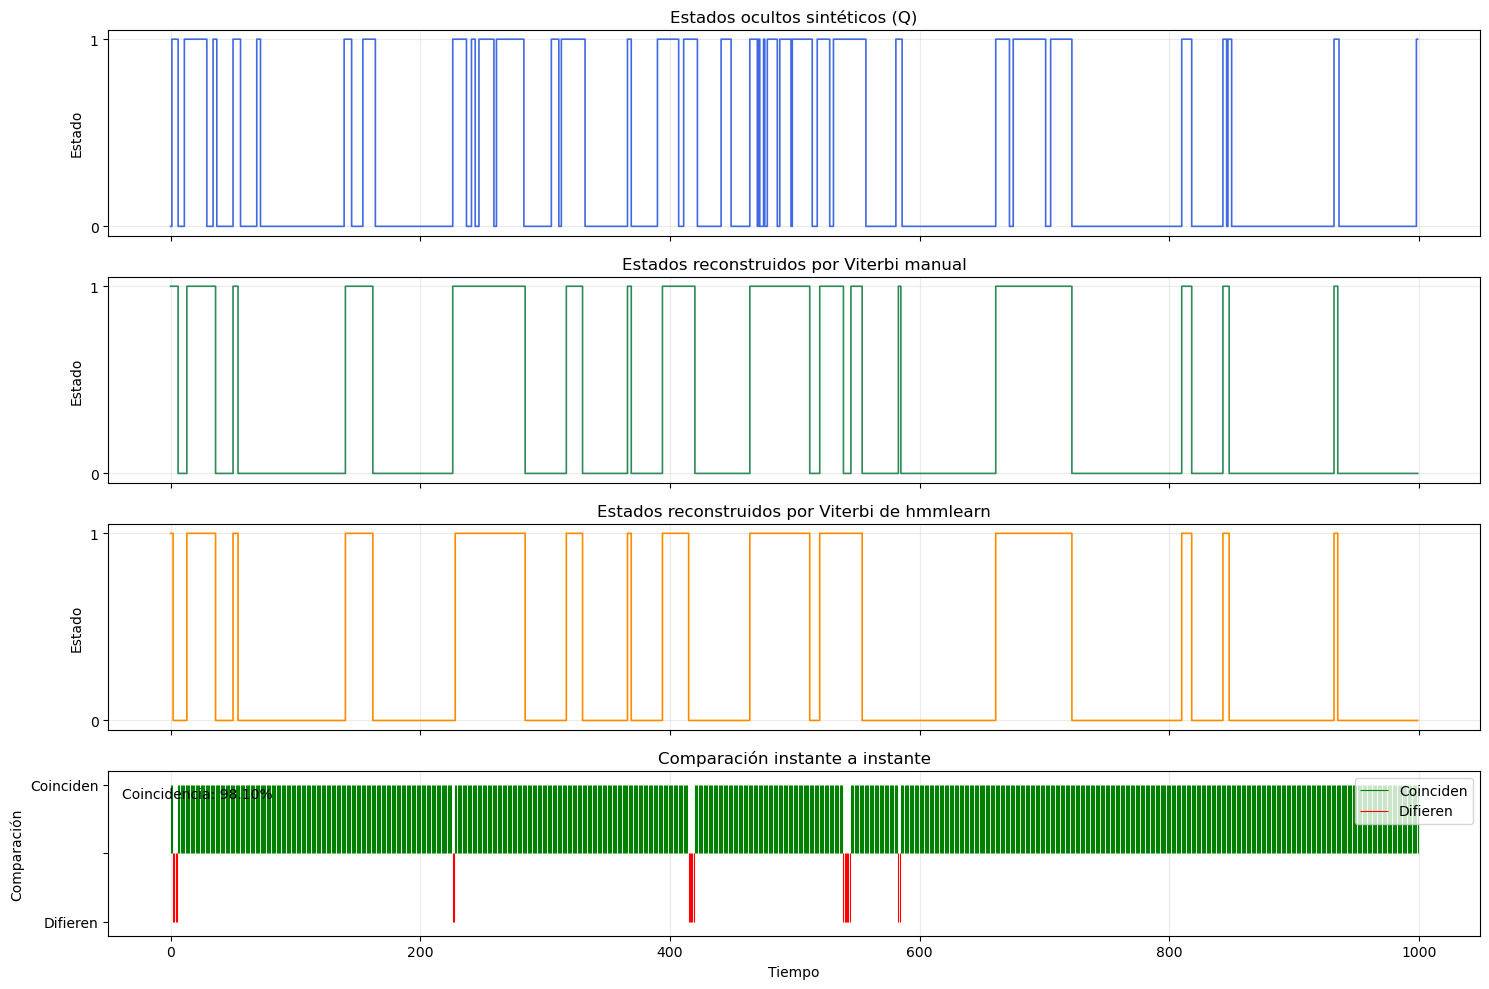

Porcentaje de coincidencia entre ambos Viterbi: 98.10%


In [10]:
correct = np.asarray(reconstruction) == np.asarray(hmmlearn_reconstruction)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(
    4, 1,
    figsize=(15, 10),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1, 1, 0.8]}
)

# Estados ocultos sintéticos
ax1.step(t, Q, where="post", color="royalblue", linewidth=1.2)
ax1.set_ylabel("Estado")
ax1.set_yticks([0, 1])
ax1.set_title("Estados ocultos sintéticos (Q)")
ax1.grid(alpha=0.25)

# Estados reconstruidos por tu Viterbi manual
ax2.step(t, reconstruction, where="post",
         color="seagreen", linewidth=1.2)
ax2.set_ylabel("Estado")
ax2.set_yticks([0, 1])
ax2.set_title("Estados reconstruidos por Viterbi manual")
ax2.grid(alpha=0.25)

# Estados reconstruidos por hmmlearn
ax3.step(t, hmmlearn_reconstruction, where="post",
         color="darkorange", linewidth=1.2)
ax3.set_ylabel("Estado")
ax3.set_yticks([0, 1])
ax3.set_title("Estados reconstruidos por Viterbi de hmmlearn")
ax3.grid(alpha=0.25)

# Comparación entre ambos algoritmos
ax4.vlines(t[correct], 0, 1, color="green", linewidth=0.8,
           label="Coinciden")
ax4.vlines(t[~correct], 0, -1, color="red", linewidth=0.8,
           label="Difieren")
ax4.set_ylim(-1.2, 1.2)
ax4.set_yticks([-1, 0, 1], labels=["Difieren", "", "Coinciden"])
ax4.set_xlabel("Tiempo")
ax4.set_ylabel("Comparación")
ax4.set_title("Comparación instante a instante")
ax4.legend(loc="upper right")
ax4.grid(axis="x", alpha=0.25)

accuracy = np.mean(correct) * 100

ax4.text(
    0.01, 0.90, f"Coincidencia: {accuracy:.2f}%",
    transform=ax4.transAxes, va="top"
)

plt.tight_layout()
plt.show()

print(f"Porcentaje de coincidencia entre ambos Viterbi: {accuracy:.2f}%")

Una última comparación entre la implementación manual y el uso de hmmlearn. En esta gráfica se puede observar las diferencias en las predicciones de ambas implementaciones. 

# Pendientes del proyecto

-  Descargar datos reales con yfinance y calcular retornos logarítmicos.
-  Preprocesar la serie y ajustar el HMM de 2 estados sobre datos reales.
-  Decodificar el régimen con Viterbi y visualizarlo sobre el precio.
-  Análisis de mecánica estadística: distribución estacionaria, entropía de transición, tiempos de residencia y autocorrelación.
-  Extender a 3 estados y comparar modelos con AIC/BIC.
-  Validar cualitativamente contra eventos reales (2008, 2020) y análisis de sensibilidad.
-  Redacción final: README, methodology.md y limpieza/comentarios de los notebooks.


**NOTA:** Aún no he migrado todas las cosas que tenía el preinforme inicialmente ya que me he concentrado más en hacer el código y hacer las explicaciones necesarias para el código. Pero lo que es el marco teórico de la parte económica más las referencias las tendré listas en el notebook al finalizar el proyecto. Además quiero ser transparente en el uso de la IA únicamente para la generación de las gráficas (busco plots que sean bonitos y gráficar no es algo que se me de muy bien) y la escritura de la tabla comparativa entre la implementación manual y el uso de hmmlearn para agilizar el tiempo de escritura. 